In [3]:
import os
import zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetV2S, DenseNet121, InceptionResNetV2, ResNet50
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
import cv2

In [4]:
UNIFIED_DATASET_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/unified_dataset"
UNIFIED_ZIP_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/unified_dataset.zip"

In [ ]:
unzip_to = UNIFIED_DATASET_PATH
zip_path = UNIFIED_ZIP_PATH
with zipfile.ZipFile(zip, 'r') as zip_ref:
    zip_ref.extractall(unzip_to)

In [5]:
TRAIN_GROUNDTRUTH_PATH = os.path.join(UNIFIED_DATASET_PATH, "gt.csv")
# TEST_GROUNDTRUTH_PATH = "/teamspace/studios/this_studio/ham10000/HAM10000_Test_GroundTruth_Updated.csv"
# TEST2_GROUNDTRUTH_PATH = "/teamspace/studios/this_studio/data/test/ISIC_2019_Test_GroundTruth.csv"

TRAIN_IMAGE_DIR = os.path.join(UNIFIED_DATASET_PATH, "images")
# TEST_IMAGE_DIR = "/teamspace/studios/this_studio/ham10000/HAM10000_images_part_12"
# TEST2_IMAGE_DIR = "/teamspace/studios/this_studio/data/test/ISIC_2019_Test_Input"
SEGM_DIR = os.path.join(UNIFIED_DATASET_PATH, "segmentations")
MODEL_NAME = "efficientnetv2-s-onehot-deep-unified-no-segm"

IMG_SIZE = (456, 456)
BATCH_SIZE = 32
EPOCHS = 20
LABELS = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

In [6]:
def read_ds(gnd_path):
    df = pd.read_csv(gnd_path)
    return df

def get_image_paths_and_labels(df, image_dir):
    image_paths = [os.path.join(image_dir, row['image'] + '.jpg') for _, row in df.iterrows()]
    labels = df[LABELS].values  # One-hot labels
    return image_paths, labels

train_groundtruth = read_ds(TRAIN_GROUNDTRUTH_PATH)
# test_groundtruth = read_ds(TEST_GROUNDTRUTH_PATH)
# test_groundtruth_2 = read_ds(TEST2_GROUNDTRUTH_PATH)

train_paths, train_labels = get_image_paths_and_labels(train_groundtruth, TRAIN_IMAGE_DIR)
# test_paths, test_labels = get_image_paths_and_labels(test_groundtruth, TEST_IMAGE_DIR)
# test_paths_2, test_labels_2 = get_image_paths_and_labels(test_groundtruth_2, TEST2_IMAGE_DIR)

In [7]:
from sklearn.model_selection import train_test_split

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    train_paths, train_labels, test_size=0.2, stratify=train_labels, random_state=42
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.5, stratify=temp_labels, random_state=42
)

In [8]:
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

def load_image2(file_path, label):
    def py_process(path_str):
        import numpy as np
        import cv2
        import os

        path_str = path_str.numpy().decode()
        img = cv2.imread(path_str)
        h, w = img.shape[:2]

        # Build segmentation path
        segm_path = os.path.join(SEGM_DIR, os.path.basename(path_str))

        # If segmentation file does not exist, return original image
        if not os.path.exists(segm_path):
            return img.astype(np.uint8)

        # Read segmentation and parse polygon
        with open(segm_path, 'r') as f:
            parts = list(map(float, f.read().strip().split()))
        coords = np.array(parts[1:], dtype=np.int32).reshape(-1, 2)

        # Create mask and apply it
        mask = np.zeros((h, w), dtype=np.uint8)
        cv2.fillPoly(mask, [coords], 1)
        mask = np.stack([mask]*3, axis=-1)
        masked = img * mask
        return masked.astype(np.uint8)

    # Apply the Python function
    img_masked = tf.py_function(py_process, [file_path], tf.uint8)
    img_masked.set_shape([None, None, 3])

    img_masked = tf.image.resize(img_masked, IMG_SIZE)
    img_masked = tf.keras.applications.efficientnet.preprocess_input(img_masked)

    return img_masked, label



def create_mask_from_polygon(polygon, height, width):
    polygon = np.array(polygon, dtype=np.int32).reshape((-1, 2))
    mask = np.zeros((height, width), dtype=np.uint8)
    cv2.fillPoly(mask, [polygon], color=1)
    return mask

def preprocess_and_augment(file_path, label):
    def py_process(path_str):
        import numpy as np
        import cv2
        import os

        path_str = path_str.numpy().decode()
        img = cv2.imread(path_str)
        h, w = img.shape[:2]

        # Build segmentation path
        segm_path = os.path.join(SEGM_DIR, os.path.basename(path_str))

        # If segmentation file does not exist, return original image
        if not os.path.exists(segm_path):
            return img.astype(np.uint8)

        # Read segmentation and parse polygon
        with open(segm_path, 'r') as f:
            parts = list(map(float, f.read().strip().split()))
        coords = np.array(parts[1:], dtype=np.int32).reshape(-1, 2)

        # Create mask and apply it
        mask = np.zeros((h, w), dtype=np.uint8)
        cv2.fillPoly(mask, [coords], 1)
        mask = np.stack([mask]*3, axis=-1)
        masked = img * mask
        return masked.astype(np.uint8)

    # Apply the Python function
    img_masked = tf.py_function(py_process, [file_path], tf.uint8)
    img_masked.set_shape([None, None, 3])

    # Resize and preprocess
    img_masked = tf.image.resize(img_masked, IMG_SIZE)
    img_masked = tf.keras.applications.efficientnet.preprocess_input(img_masked)

    # Augmentation
    img_masked = tf.image.random_flip_left_right(img_masked)
    img_masked = tf.image.random_flip_up_down(img_masked)
    img_masked = tf.image.random_brightness(img_masked, max_delta=0.2)
    img_masked = tf.image.random_contrast(img_masked, lower=0.8, upper=1.2)

    return img_masked, label



train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(load_image2).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(load_image2).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


2025-05-09 20:40:11.246957: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-05-09 20:40:11.247000: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2025-05-09 20:40:11.247004: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 10.67 GB
I0000 00:00:1746812411.247441 22802144 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1746812411.247692 22802144 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [9]:
def show_image(paths):
  # Find a valid image path with a corresponding .txt segmentation file
  for path in paths:
      base_filename = os.path.basename(path).split('.')[0]
      segm_path = os.path.join(SEGM_DIR, base_filename + '.txt')

      if os.path.exists(segm_path):
          print("Found matching image and segmentation file:")
          print("Image path:", path)
          print("Segmentation path:", segm_path)

          # Convert to Tensor
          path_tensor = tf.convert_to_tensor(path, dtype=tf.string)
          dummy_label = tf.constant(0)  # You can use any dummy label here

          # Apply the function
          processed_img_tensor, _ = preprocess_and_augment(path_tensor, dummy_label)

          # Convert tensor to NumPy for visualization
          processed_img = processed_img_tensor.numpy()
          processed_img = (processed_img - processed_img.min()) / (processed_img.max() - processed_img.min())  # Normalize for display

          plt.imshow(processed_img)
          plt.title("Preprocessed + Augmented Image")
          plt.axis("off")
          plt.show()
          break
  else:
      print("No matching image and segmentation file found.")


Found matching image and segmentation file:
Image path: /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/images/ISIC_0026772.jpg
Segmentation path: /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/segmentations/ISIC_0026772.txt


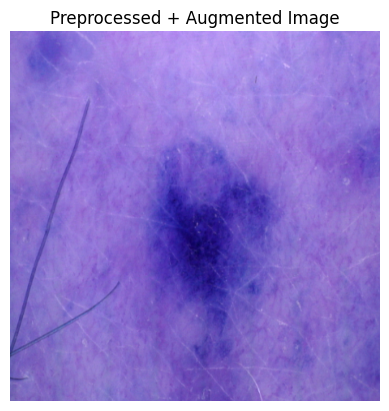

In [10]:
show_image(train_paths)

In [27]:
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

def preprocess_and_augment(file_path, label):
    img, label = load_image(file_path, label)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.2)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
    return img, label

train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


In [11]:
def build_model():
    base_model = DenseNet121(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
    
    base_model.trainable = True
    for layer in base_model.layers[:int(len(base_model.layers) * 0.7)]:
        layer.trainable = False 

    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = base_model(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x) 


    x = layers.Dense(2048, activation="mish")(x)  
    x = layers.Dropout(0.4)(x)  
    x = layers.LayerNormalization()(x)  

    x = layers.Dense(1024, activation="mish")(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(512, activation="mish")(x)
    x = layers.Dropout(0.2)(x)

    se = layers.Lambda(lambda t: tf.expand_dims(t, axis=-1))(x) 
    se = layers.GlobalAveragePooling1D()(se)
    se = layers.Dense(64, activation="relu")(se)
    se = layers.Dense(512, activation="sigmoid")(se)
    x = layers.Multiply()([x, se])

    outputs = layers.Dense(len(LABELS), activation="softmax")(x)
    model = models.Model(inputs, outputs)

    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

    model.compile(
        optimizer=optimizer, 
        loss="categorical_crossentropy",  
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"), 
            tf.keras.metrics.Recall(name="recall")
        ]
)


    return model

model = build_model()


In [12]:
train_labels_argmax = np.argmax(train_labels, axis=1)
class_weights = compute_class_weight(class_weight="balanced", classes=np.arange(len(LABELS)), y=train_labels_argmax)
class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}

In [25]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 456, 456,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2-s    │ (None, 15, 15,    │ 20,331,360 │ input_layer_1[0]… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetv2-s… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 2048)      │  2,623,488 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 2048)      │      4,096 │ dropout[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1024)      │  2,098,176 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 1024)      │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 512)       │    524,800 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 512)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 512, 1)    │          0 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1)         │          0 │ lambda[0][0]      │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │        128 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 512)       │     33,280 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 512)       │          0 │ dropout_2[0][0],  │
│                     │                   │            │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 8)         │      4,104 │ multiply[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 25,619,432 (97.73 MB)

 Trainable params: 15,669,512 (59.77 MB)

 Non-trainable params: 9,949,920 (37.96 MB)

In [ ]:
checkpoint = ModelCheckpoint(f"{MODEL_NAME}_baserun.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20


In [32]:
checkpoint = ModelCheckpoint(f"{MODEL_NAME}_baserun_2.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history2 = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20
424/519 ━━━━━━━━━━━━━━━━━━━━ 2:19 1s/step - accuracy: 0.8093 - auc: 0.9820 - loss: 0.2905 - precision: 0.8333 - recall: 0.7898

KeyboardInterrupt: 

### Soft masking

In [14]:
def create_mask_from_polygon(polygon, height, width):
    polygon = np.array(polygon, dtype=np.int32).reshape((-1, 2))
    mask = np.zeros((height, width), dtype=np.uint8)
    cv2.fillPoly(mask, [polygon], color=1)
    return mask

def soft_mask(path_str):
    import numpy as np
    import cv2
    import os

    path_str = path_str.numpy().decode()
    img = cv2.imread(path_str)
    if img is None:
        raise ValueError(f"Could not read image at {path_str}")
    h, w = img.shape[:2]

    # Build segmentation path
    segm_path = os.path.join(SEGM_DIR, os.path.basename(path_str).split('.')[0] + '.txt')

    # If segmentation file does not exist, return original image
    if not os.path.exists(segm_path):
        return img.astype(np.uint8)

    # Read segmentation and parse polygon
    with open(segm_path, 'r') as f:
        parts = list(map(float, f.read().strip().split()))
    if len(parts) < 3:
        return img.astype(np.uint8)
    
    polygon_normalized = parts[1:]  # skip class id

    # If odd number of values, trim the last one
    if len(polygon_normalized) % 2 != 0:
        polygon_normalized = polygon_normalized[:-1]  # remove last

    if len(polygon_normalized) < 2:
        return img.astype(np.uint8)
    
    # Denormalize coordinates
    polygon = [(int(polygon_normalized[i] * w), int(polygon_normalized[i + 1] * h)) 
               for i in range(0, len(polygon_normalized), 2)]

    # Create mask
    mask = create_mask_from_polygon(polygon, h, w)  # binary 0/1
    mask_3c = np.stack([mask]*3, axis=-1).astype(np.float32)

    # Soft mask: keep full object, dim background
    background_fade = 0.3
    blended = (img * mask_3c + img * (1 - mask_3c) * background_fade).astype(np.uint8)
    return blended



def segment(file_path, label):
    img = tf.py_function(soft_mask, [file_path], tf.uint8)
    img.set_shape([None, None, 3])

    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.efficientnet.preprocess_input(img)

    return img, label


def preprocess_and_augment(file_path, label):
    # Apply the Python function
    img, label = segment(file_path, label)

    # Augmentation
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.2)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)

    return img, label

In [15]:
train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(segment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(segment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

Found matching image and segmentation file:
Image path: /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/images/ISIC_0026772.jpg
Segmentation path: /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/segmentations/ISIC_0026772.txt


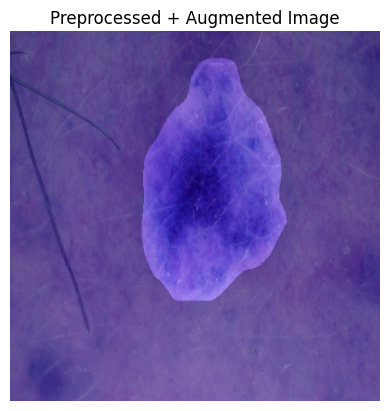

In [71]:
import os
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf

# Find a valid image path with a corresponding .txt segmentation file
for path in train_paths:
    base_filename = os.path.basename(path).split('.')[0]
    segm_path = os.path.join(SEGM_DIR, base_filename + '.txt')

    if os.path.exists(segm_path):
        print("Found matching image and segmentation file:")
        print("Image path:", path)
        print("Segmentation path:", segm_path)

        # Convert to Tensor
        path_tensor = tf.convert_to_tensor(path, dtype=tf.string)
        dummy_label = tf.constant(0)  # You can use any dummy label here

        # Apply the function
        processed_img_tensor, _ = preprocess_and_augment(path_tensor, dummy_label)

        # Convert tensor to NumPy for visualization
        processed_img = processed_img_tensor.numpy()
        processed_img = (processed_img - processed_img.min()) / (processed_img.max() - processed_img.min())  # Normalize for display

        plt.imshow(processed_img)
        plt.title("Preprocessed + Augmented Image")
        plt.axis("off")
        plt.show()
        break
else:
    print("No matching image and segmentation file found.")


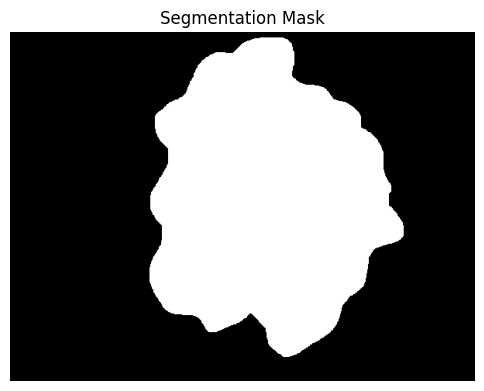

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os
zip = __builtins__.zip 
# Example: take one image file from the segmentations folder
image_path = "/Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/images/ISIC_0024306.jpg"
segm_path = os.path.join(SEGM_DIR, os.path.basename(image_path).split('.')[0]+'.txt')

# Load image to get dimensions
image = cv2.imread(image_path)
if image is None:
    raise ValueError(f"Could not read image {image_path}")
h, w = image.shape[:2]

# Create empty mask
mask = np.zeros((h, w), dtype=np.uint8)

# Parse segmentation .txt file
if os.path.exists(segm_path):
    with open(segm_path, 'r') as f:
        for line in f:
            parts = list(map(float, line.strip().split()))  # Ensure all parts are floats
            if len(parts) < 7:
                continue  # at least 3 points
            
            class_id = int(parts[0])  # First element is the class id
            coords_normalized = parts[1:]  # Remaining are the normalized coordinates
            
            # Create points by denormalizing the coordinates
            points = [(int(x * w), int(y * h)) for x, y in zip(coords_normalized[::2], coords_normalized[1::2])]
            
            # Convert points into a polygon and fill it in the mask
            polygon = np.array(points, dtype=np.int32)
            cv2.fillPoly(mask, [polygon], color=1)

# Show the binary mask
plt.figure(figsize=(6, 6))
plt.imshow(mask, cmap='gray')
plt.title("Segmentation Mask")
plt.axis("off")
plt.show()

In [39]:
model = build_model()
checkpoint = ModelCheckpoint(f"{MODEL_NAME}_softmask_baserun_2.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history2 = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20


2025-05-07 10:22:03.737125: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:79: Filling up shuffle buffer (this may take a while): 470 of 512
2025-05-07 10:22:04.211782: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


519/519 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3757 - auc: 0.7731 - loss: 1.7857 - precision: 0.6335 - recall: 0.1381
Epoch 1: val_accuracy improved from -inf to 0.36276, saving model to efficientnetv2-s-onehot-deep-unified_softmask_baserun_2.keras
519/519 ━━━━━━━━━━━━━━━━━━━━ 945s 2s/step - accuracy: 0.3758 - auc: 0.7732 - loss: 1.7852 - precision: 0.6335 - recall: 0.1383 - val_accuracy: 0.3628 - val_auc: 0.7839 - val_loss: 1.8427 - val_precision: 0.4203 - val_recall: 0.2441 - learning_rate: 1.0000e-04
Epoch 2/20
519/519 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5370 - auc: 0.8864 - loss: 1.1920 - precision: 0.6524 - recall: 0.4154
Epoch 2: val_accuracy improved from 0.36276 to 0.38543, saving model to efficientnetv2-s-onehot-deep-unified_softmask_baserun_2.keras
519/519 ━━━━━━━━━━━━━━━━━━━━ 774s 1s/step - accuracy: 0.5370 - auc: 0.8864 - loss: 1.1919 - precision: 0.6524 - recall: 0.4155 - val_accuracy: 0.3854 - val_auc: 0.8042 - val_loss: 1.8802 - val_precision: 0.4135 - v

KeyboardInterrupt: 

In [28]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot-deep-split_baserun_2.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history3 = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step - accuracy: 0.9421 - auc: 0.9978 - loss: 0.0734 - precision: 0.9478 - recall: 0.9387
Epoch 1: val_accuracy improved from -inf to 0.83853, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 233s 359ms/step - accuracy: 0.9421 - auc: 0.9978 - loss: 0.0734 - precision: 0.9478 - recall: 0.9387 - val_accuracy: 0.8385 - val_auc: 0.9683 - val_loss: 0.6954 - val_precision: 0.8415 - val_recall: 0.8362 - learning_rate: 1.0000e-06
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.9399 - auc: 0.9973 - loss: 0.0809 - precision: 0.9441 - recall: 0.9372
Epoch 2: val_accuracy improved from 0.83853 to 0.84366, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 232s 358ms/step - accuracy: 0.9399 - auc: 0.9973 - loss: 0.0809 - precision: 0.9441 - recall: 0.9372 - val_accuracy: 0.8437 - val_auc: 0.9700 - val_loss: 0.6858 - val_precision: 0.8460 

58/80 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.8440 - auc: 0.9662 - loss: 0.7485 - precision: 0.8475 - recall: 0.8404

80/80 ━━━━━━━━━━━━━━━━━━━━ 23s 290ms/step - accuracy: 0.8459 - auc: 0.9671 - loss: 0.7300 - precision: 0.8493 - recall: 0.8426


2025-03-17 16:26:08.087515: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


80/80 ━━━━━━━━━━━━━━━━━━━━ 31s 278ms/step
              precision    recall  f1-score   support

         MEL       0.74      0.78      0.76       452
          NV       0.92      0.89      0.90      1288
         BCC       0.87      0.93      0.90       333
          AK       0.69      0.76      0.72        86
         BKL       0.79      0.76      0.77       263
          DF       0.75      0.75      0.75        24
        VASC       0.85      0.88      0.86        25
         SCC       0.73      0.70      0.72        63

    accuracy                           0.85      2534
   macro avg       0.79      0.81      0.80      2534
weighted avg       0.85      0.85      0.85      2534



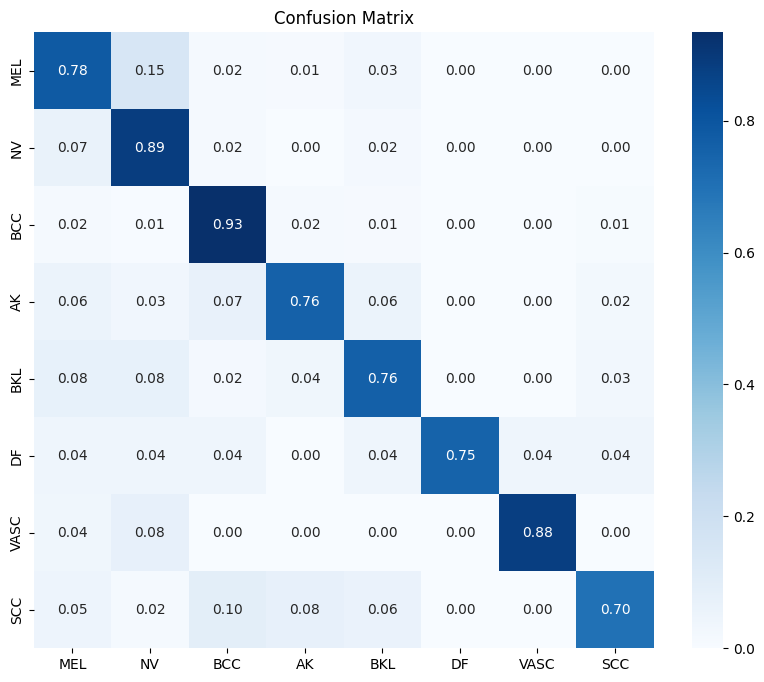

In [29]:
result = model.evaluate(test_dataset)
y_true = np.argmax(np.concatenate([y.numpy() for _, y in test_dataset]), axis=1)
y_pred = np.argmax(model.predict(test_dataset), axis=1)

print(classification_report(y_true, y_pred, target_names=LABELS))

conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f", xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

# Fine-tuning

In [18]:
tf.compat.v1.enable_eager_execution()
model = tf.keras.models.load_model('/teamspace/studios/this_studio/models/weights/efficientnet-v2-m-onehot_baserun.keras')

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 1308 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [15]:
model.evaluate(test_dataset_2)

258/258 ━━━━━━━━━━━━━━━━━━━━ 580s 2s/step - accuracy: 0.5873 - loss: 0.8531 - precision: 0.6827 - recall: 0.5625


[0.8416513204574585,
 0.4922311305999756,
 0.5843790769577026,
 0.5039573311805725]

In [20]:
for layer in model.layers:
     if layer.name == 'efficientnetv2-m':
         layer.trainable = True
         for l in layer.layers[:-200]:
              l.trainable = False
         for l in layer.layers[-200:]:
              l.trainable = True
     if layer.name == 'batch_normalization_1':
         layer.trainable = False
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-m (Functional)   │ (None, 15, 15, 1280)   │    53,150,388 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         8,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,835,126 (621.17 MB)

 Trainable params: 31,530,196 (120.28 MB)

 Non-trainable params: 22,944,232 (87.53 MB)

 Optimizer params: 108,360,698 (413.36 MB)

In [21]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot_finetuning.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
history = model.fit(train_dataset, validation_data=test_dataset, epochs=EPOCHS, callbacks=[checkpoint],
                    class_weight=class_weights_dict)

Epoch 1/20


792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6119 - loss: 0.9054 - precision: 0.6894 - recall: 0.5100
Epoch 1: val_accuracy improved from -inf to 0.56555, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2619s 3s/step - accuracy: 0.6118 - loss: 0.9058 - precision: 0.6894 - recall: 0.5099 - val_accuracy: 0.5656 - val_loss: 1.2173 - val_precision: 0.6631 - val_recall: 0.4442
Epoch 2/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6558 - loss: 0.6761 - precision: 0.7386 - recall: 0.5603
Epoch 2: val_accuracy improved from 0.56555 to 0.62566, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2177s 3s/step - accuracy: 0.6558 - loss: 0.6764 - precision: 0.7386 - recall: 0.5603 - val_accuracy: 0.6257 - val_loss: 1.0137 - val_precision: 0.6772 - val_recall: 0.5494
Epoch 3/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6923 - loss: 0.5476 - precision: 0.7503 - recall: 0.6250
Epoch 3: val_accur

KeyboardInterrupt: 

In [ ]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot_finetuning.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
history = model.fit(train_dataset, validation_data=test_dataset_2, epochs=EPOCHS, callbacks=[checkpoint],
                    class_weight=class_weights_dict)

Epoch 1/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7569 - loss: 0.3798 - precision: 0.7922 - recall: 0.7203
Epoch 1: val_accuracy improved from -inf to 0.50522, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2074s 3s/step - accuracy: 0.7570 - loss: 0.3799 - precision: 0.7922 - recall: 0.7203 - val_accuracy: 0.5052 - val_loss: 0.9712 - val_precision: 0.5086 - val_recall: 0.6099
Epoch 2/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7700 - loss: 0.3524 - precision: 0.7983 - recall: 0.7368
Epoch 2: val_accuracy did not improve from 0.50522
792/792 ━━━━━━━━━━━━━━━━━━━━ 2025s 3s/step - accuracy: 0.7700 - loss: 0.3524 - precision: 0.7984 - recall: 0.7369 - val_accuracy: 0.4942 - val_loss: 1.1084 - val_precision: 0.4868 - val_recall: 0.5870
Epoch 3/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7780 - loss: 0.3390 - precision: 0.8038 - recall: 0.7458
Epoch 3: val_accuracy improved from 0.50522 to 0.51238, saving model t

In [40]:
model.save('efficientnet-v2-m-onehot_baserun.keras')

In [11]:
import pandas as pd

metadata = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/ISIC_2020_Dataset/ISIC_2020_Train_Metadata.csv')
metadata_2019 = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Metadata.csv')
# Filter out rows where the diagnosis is 'unknown'
metadata_filtered = metadata[metadata['diagnosis'] == 'melanoma']

# Check if the image names in 'metadata' are not in 'metadata_2019'
metadata_filtered = metadata_filtered[~metadata_filtered['image_name'].isin(metadata_2019['image'])]

# Show the result
print(metadata_filtered)

         image_name  patient_id   lesion_id     sex  age_approx  \
91     ISIC_0149568  IP_0962375  IL_6540984  female        55.0   
235    ISIC_0188432  IP_0135517  IL_7870569  female        50.0   
314    ISIC_0207268  IP_7735373  IL_1066532    male        55.0   
399    ISIC_0232101  IP_8349964  IL_8939481    male        65.0   
459    ISIC_0247330  IP_3232631  IL_3206110  female        65.0   
...             ...         ...         ...     ...         ...   
32969  ISIC_9955163  IP_7507212  IL_4873145    male        55.0   
33000  ISIC_9963177  IP_1165806  IL_0973502    male        70.0   
33014  ISIC_9967383  IP_7887363  IL_2267077    male        60.0   
33050  ISIC_9978107  IP_2860540  IL_8465436    male        65.0   
33117  ISIC_9998682  IP_2516168  IL_1802809    male        60.0   

      anatom_site_general_challenge diagnosis benign_malignant  target  
91                  upper extremity  melanoma        malignant       1  
235                 upper extremity  melanoma    

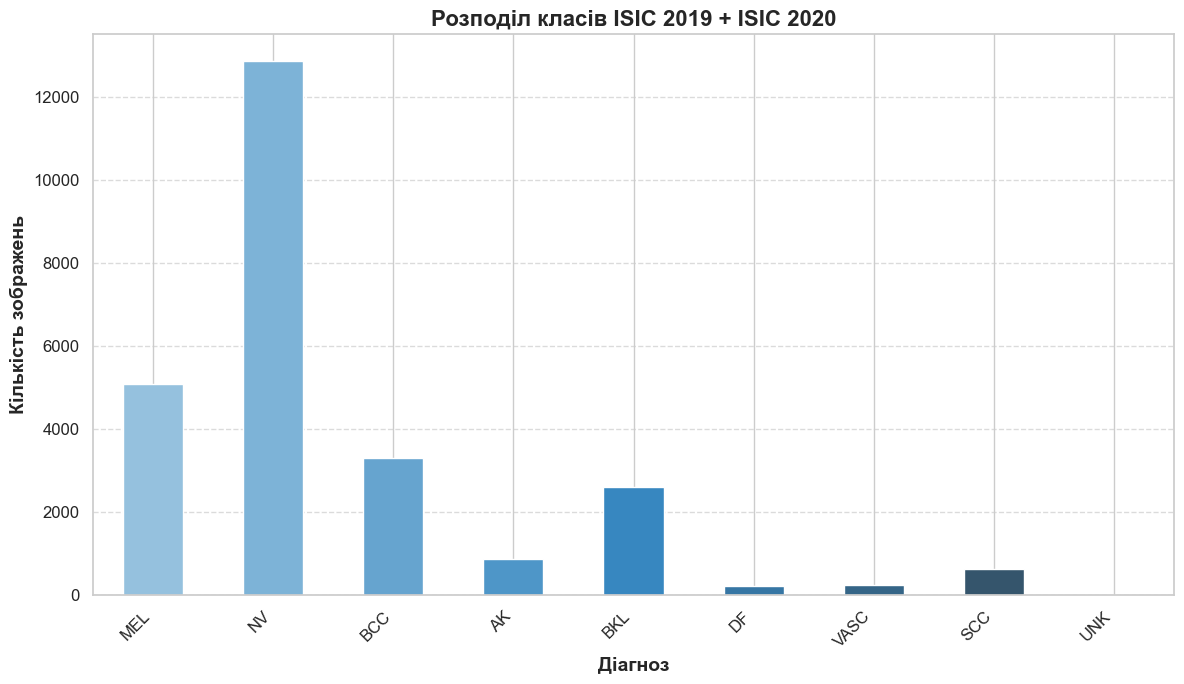

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the metadata for ISIC 2019
metadata_2019 = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Groundtruth.csv')

# Sum up the values for each class (ignoring the 'image' column)
class_counts = metadata_2019.drop(columns=['image']).sum()

# Add 584 to the 'MEL' class count as per your request
class_counts['MEL'] += 584

# Set a modern Seaborn style
sns.set(style="whitegrid")

# Create the plot with custom colors from Seaborn's palette
plt.figure(figsize=(12, 7))
ax = class_counts.plot(kind='bar', color=sns.color_palette("Blues_d", len(class_counts)))

# Adding a title and labels with modern fonts
plt.title('Розподіл класів ISIC 2019 + ISIC 2020', fontsize=16, fontweight='bold')
plt.xlabel('Діагноз', fontsize=14, fontweight='bold')
plt.ylabel('Кількість зображень', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)

# Add a grid for better readability on the y-axis
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# Tight layout to make sure labels don't get cut off
plt.tight_layout()

# Show the plot
plt.show()


In [ ]:
def plot_history(history_dict):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    
    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label=f'Train {metric}')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label=f'Validation {metric}')
            plt.title(f'{metric.capitalize()} Over Epochs')
            plt.xlabel('Epochs')
            plt.ylabel(metric.capitalize())
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()


In [ ]:
plot_history(history3.history)

In [9]:
## Testing models
models_paths = ["/Users/mac/Development/diploma/skin-mutation-detection/models/weights/resnet50-onehot-deep-unified_softmask_baserun_2.keras", 
                "/Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnetv2-s-onehot-deep-unified_softmask_baserun_2.keras"]


#### (1) Using only the pre-defined lesion segmentations

In [16]:
SEGM_DIR = os.path.join(UNIFIED_DATASET_PATH, "segmentations")
test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(segment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


81/81 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.7314 - auc: 0.9458 - loss: 0.9560 - precision: 0.7428 - recall: 0.7197
81/81 ━━━━━━━━━━━━━━━━━━━━ 87s 977ms/step
              precision    recall  f1-score   support

         MEL       0.69      0.68      0.68       511
          NV       0.86      0.76      0.81      1288
         BCC       0.77      0.88      0.82       332
          AK       0.57      0.57      0.57        86
         BKL       0.53      0.63      0.58       263
          DF       0.42      0.46      0.44        24
        VASC       0.33      0.92      0.48        25
         SCC       0.49      0.65      0.56        63

    accuracy                           0.73      2592
   macro avg       0.58      0.69      0.62      2592
weighted avg       0.75      0.73      0.74      2592



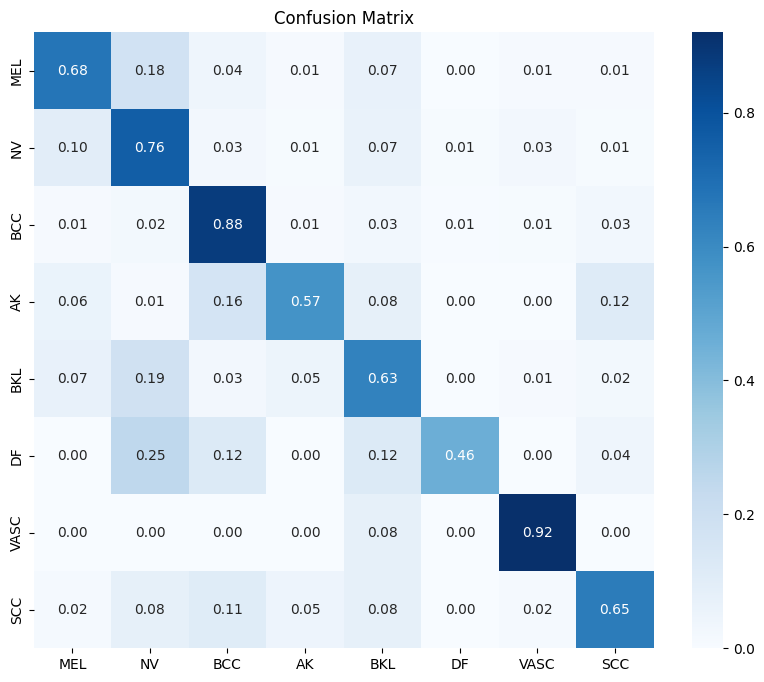

In [ ]:
tf.keras.config.enable_unsafe_deserialization()
result = model.evaluate(test_dataset)
y_true = np.argmax(np.concatenate([y.numpy() for _, y in test_dataset]), axis=1)
y_pred = np.argmax(model.predict(test_dataset), axis=1)

print(classification_report(y_true, y_pred, target_names=LABELS))

conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f", xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()


#### (2) Using YOLO model to segment, and feed afterwards

In [ ]:
import os
import cv2
import numpy as np
from ultralytics import YOLO
import tensorflow as tf

# Define temp directory for saving YOLO formatted txt files
TEMP_DIR = "temp_segmentation_files"
os.makedirs(TEMP_DIR, exist_ok=True)

# Load the YOLO model for segmentation
yolo_model = YOLO("/Users/mac/Development/diploma/skin-mutation-detection/models/weights/yolo-isic-segm.pt")  # Use your custom model if needed

def save_yolo_format(segmentation_result, output_path, img_width, img_height):
    """
    Save segmentation result to YOLO format (polygon coordinates).
    """
    with open(output_path, 'w') as f:
        class_id = segmentation_result['class_id']
        polygon = segmentation_result['polygon']  # Assumed to be a list of (x, y) pairs
            
        # Normalize the coordinates to YOLO format
        normalized_polygon = []
        for (x, y) in polygon:
            normalized_polygon.append(x / img_width)
            normalized_polygon.append(y / img_height)
        
        # Write in the YOLO format: class_id and normalized (x, y) coordinates
        f.write(f"{class_id} " + " ".join(map(str, normalized_polygon)) + "\n")

def perform_yolo_segmentation(image_path, output_txt_path):
    """
    Perform segmentation on the input image and save the result in YOLO format.
    """
    # Load the image and get its dimensions
    img = cv2.imread(image_path)
    img_height, img_width = img.shape[:2]

    # Perform segmentation
    results = yolo_model(image_path)  # returns results as a list of Detection objects
    
    # Find the most probable result (with highest confidence score)
    if results[0].masks is not None:  # Check if masks are available
        most_probable_mask = None
        highest_confidence = -1  # Initialize to an impossible low confidence

        # Loop through each mask and select the one with the highest confidence
        for idx, result in enumerate(results[0].masks):  # Loop over each mask (segmentation)
            confidence = results[0].boxes[idx].conf  # Confidence score of the detection

            # Select the mask with the highest confidence score
            if confidence > highest_confidence:
                highest_confidence = confidence
                most_probable_mask = result  # Update with the most probable mask

        if most_probable_mask is not None:
            # Extract the class ID and polygon from the most probable mask
            class_id = int(results[0].boxes[idx].cls)  # Get class ID from bounding box
            polygon = most_probable_mask.xy[0].tolist()  # Get polygon points from mask result

            # Store the result (class_id and polygon)
            segmentation_result = {
                'class_id': class_id,
                'polygon': polygon
            }

            # Save the segmentation result to YOLO format
            save_yolo_format(segmentation_result, output_txt_path, img_width, img_height)

def segment_and_save(image_path):
    """
    Perform segmentation on a single image and save the result in YOLO format.
    """
    output_txt_path = os.path.join(TEMP_DIR, os.path.basename(image_path).replace('.jpg', '.txt'))
    perform_yolo_segmentation(image_path, output_txt_path)

# Iterate over the test_dataset and apply segmentation
for image_path, _ in test_dataset:
    image_path = image_path.numpy().decode()  # Convert TensorFlow EagerTensor to string
    segment_and_save(image_path)


TypeError: expected str, bytes or os.PathLike object, not EagerTensor

In [23]:
SEGM_DIR =  "temp_segmentation_files"
test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(segment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [24]:
metrics = model.evaluate(test_dataset)

81/81 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - accuracy: 0.6467 - auc: 0.9099 - loss: 1.4111 - precision: 0.6602 - recall: 0.6351


In [25]:
labeled_metrics = result
yolo_metrics = metrics
labeled_metrics, yolo_metrics

([0.9764968752861023,
  0.7337962985038757,
  0.9439905881881714,
  0.745230495929718,
  0.7233796119689941],
 [1.4433308839797974,
  0.647376537322998,
  0.9069085121154785,
  0.6603773832321167,
  0.6346450448036194])

In [13]:
def plot_history(history_dict):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Точність',
        'loss': 'Втрата',
        'auc': 'Площа під кривою (AUC)',
        'precision': 'Влучність',
        'recall': 'Повнота'
    }

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label=f'Навчальний набір')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label=f'Валідаційний набір')
            plt.title(f'{metric_labels[metric]} за епохами')
            plt.xlabel('Епохи')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()


In [ ]:
plot_history(history3.history)

In [14]:
def plot_history(history_dict):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Accuracy',
        'loss': 'Loss',
        'auc': 'Area Under Curve (AUC)',
        'precision': 'Precision',
        'recall': 'Recall'
    }

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label='Training Set')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label='Validation Set')
            plt.title(f'{metric_labels[metric]} over Epochs')
            plt.xlabel('Epochs')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()


In [15]:
model = build_model()
model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/weights/densenet121-onehot-deep-unified_softmask_baserun_2_no_segm.keras")

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 250 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [16]:
import json
TRAIN_RESULT_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/models/results/densenet-no-segm-20.json"

with open(TRAIN_RESULT_PATH) as f:
    history = json.loads(f.read())

In [ ]:
def plot_history_ukr(history_dict, output_dir, model_name, lang_code='ukr'):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Точність',
        'loss': 'Втрата',
        'auc': 'Площа під кривою (AUC)',
        'precision': 'Влучність',
        'recall': 'Повнота'
    }

    os.makedirs(output_dir, exist_ok=True)

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label='Навчальний набір')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label='Валідаційний набір')
            plt.title(f'{metric_labels[metric]} протягом епох')
            plt.xlabel('Епохи')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()

            # Generate filename and save plot
            filename = f"{model_name}-{metric}-{lang_code}.png"
            filepath = os.path.join(output_dir, filename)
            plt.savefig(filepath)
            plt.close()


In [ ]:
def plot_history(history_dict, output_dir, model_name, lang_code="eng"):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Accuracy',
        'loss': 'Loss',
        'auc': 'Area Under Curve (AUC)',
        'precision': 'Precision',
        'recall': 'Recall'
    }

    os.makedirs(output_dir, exist_ok=True)

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label='Training Set')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label='Validation Set')
            plt.title(f'{metric_labels[metric]} over Epochs')
            plt.xlabel('Epochs')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()

            # Generate filename and save plot
            filename = f"{model_name}-{metric}-{lang_code}.png"
            filepath = os.path.join(output_dir, filename)
            plt.savefig(filepath)
            plt.close()


In [ ]:
from tqdm import tqdm
def confusion(model, ds):
  tf.keras.config.enable_unsafe_deserialization()
  # model.load_weights(f"{MODEL_NAME}_softmask_baserun_2.keras")
  result = model.evaluate(ds)
  print(result)
  y_true = np.argmax(np.concatenate([y.numpy() for _, y in tqdm(ds)]), axis=1)
  y_pred = np.argmax(model.predict(ds), axis=1)

  print(classification_report(y_true, y_pred, target_names=LABELS))

  conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
  plt.figure(figsize=(10, 8))
  sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f", xticklabels=LABELS, yticklabels=LABELS)
  plt.title("Confusion Matrix")
  plt.show()

def test_model(model, history, model_name, output_dir):
  print(history)
  plot_history(history, output_dir, model_name)
  plot_history_ukr(history, output_dir, model_name)
  train_eval_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
  train_eval_dataset = train_eval_dataset.map(preprocess_and_augment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

  for dataset, label in zip([train_eval_dataset, val_dataset, test_dataset], ['train', 'val', 'test']):
    print(f"#####  {label}  #####")
    confusion(model, dataset)


{'accuracy': [0.375, 0.5426, 0.5892, 0.6239, 0.6716, 0.6992, 0.716, 0.749, 0.7631, 0.7719, 0.7799, 0.7805, 0.7895, 0.8, 0.8054, 0.8052, 0.8032, 0.816, 0.8071, 0.8118], 'auc': [0.7823, 0.8926, 0.9164, 0.9282, 0.9467, 0.955, 0.9611, 0.9683, 0.9711, 0.9731, 0.975, 0.9762, 0.978, 0.9794, 0.9794, 0.9804, 0.9802, 0.9825, 0.9808, 0.9813], 'loss': [1.7862, 1.1823, 0.9366, 0.8421, 0.698, 0.5953, 0.5229, 0.4591, 0.4055, 0.3946, 0.3797, 0.3737, 0.3566, 0.3179, 0.32, 0.3036, 0.3117, 0.277, 0.3126, 0.3017], 'precision': [0.615, 0.6557, 0.6732, 0.6858, 0.7315, 0.7506, 0.7591, 0.7909, 0.7995, 0.8025, 0.8103, 0.8113, 0.8195, 0.8285, 0.8338, 0.8297, 0.8297, 0.8406, 0.8311, 0.8354], 'recall': [0.1465, 0.4163, 0.4995, 0.5421, 0.6082, 0.6415, 0.6701, 0.7081, 0.7276, 0.7395, 0.743, 0.7525, 0.7625, 0.7753, 0.7791, 0.7805, 0.7809, 0.7914, 0.7838, 0.7897], 'val_accuracy': [0.369, 0.3599, 0.3932, 0.4033, 0.4211, 0.4342, 0.452, 0.48, 0.4805, 0.4366, 0.4776, 0.4954, 0.4945, 0.4973, 0.479, 0.494, 0.4843, 0.4935, 

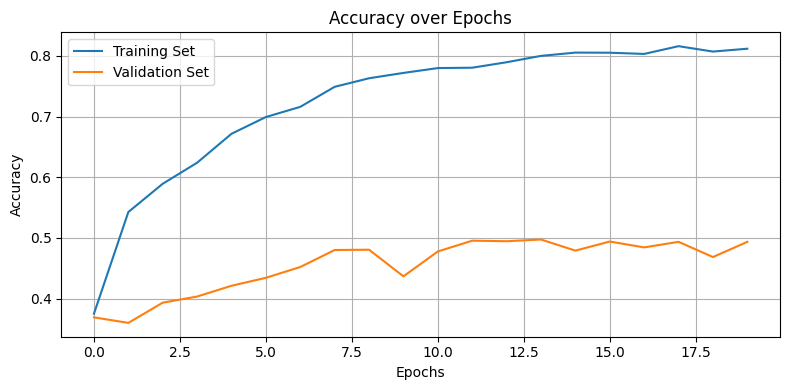

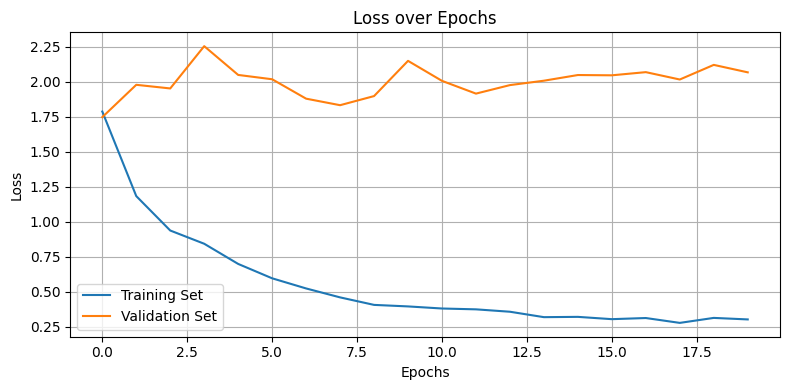

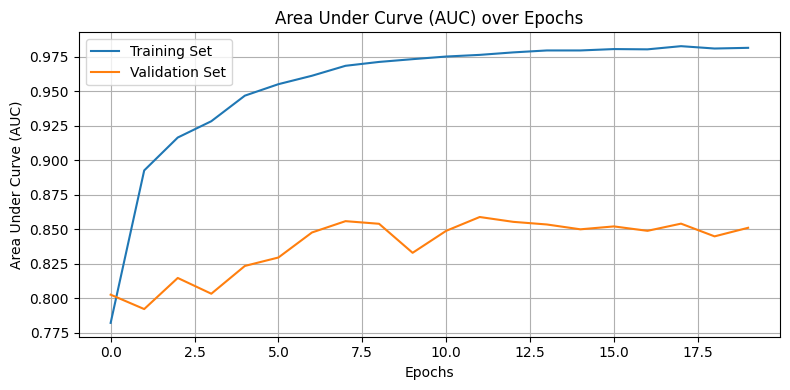

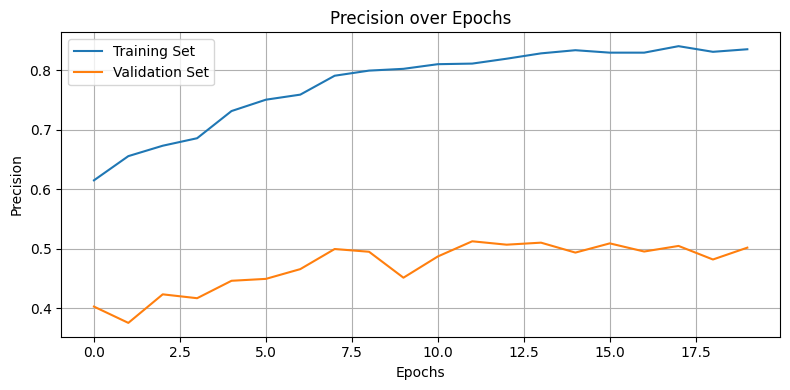

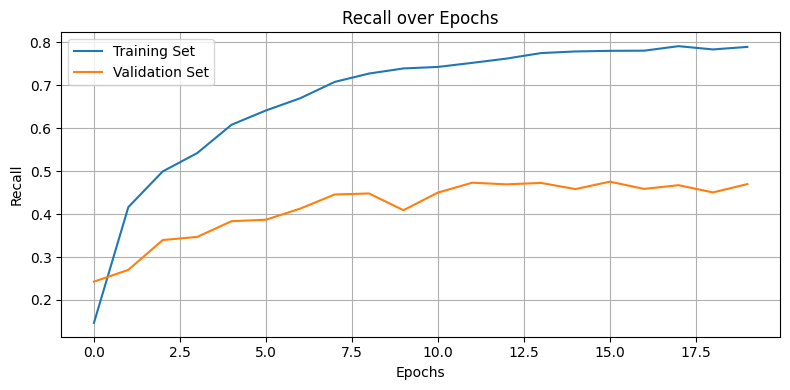

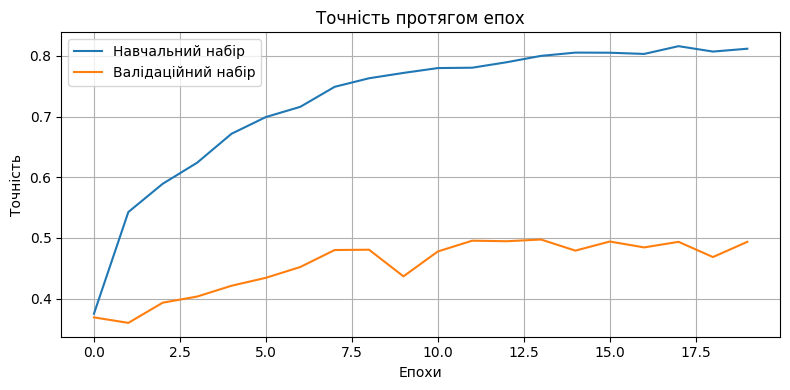

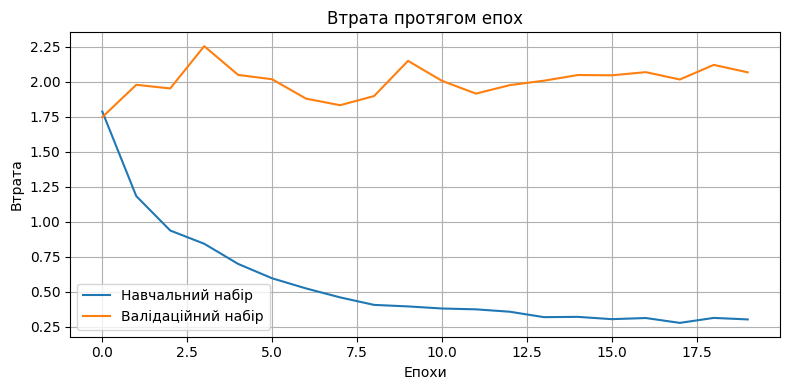

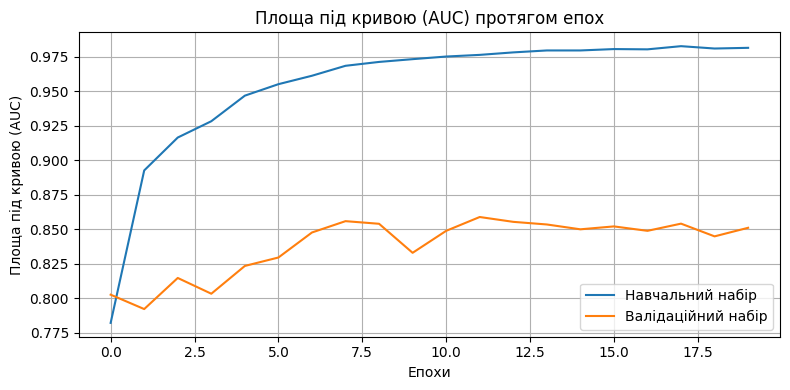

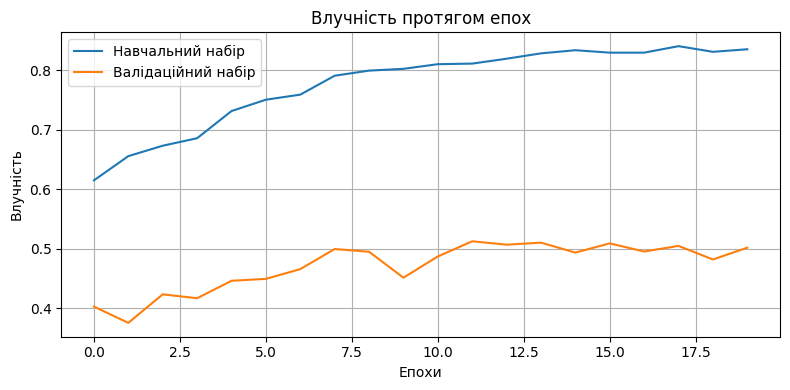

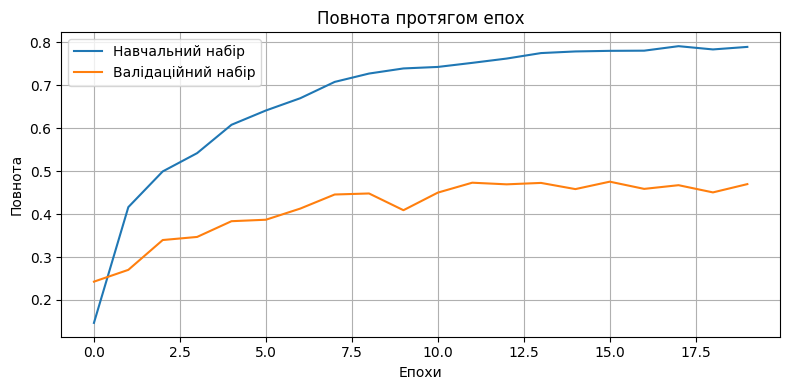

#####  train  #####


2025-05-09 20:41:01.409606: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


648/648 ━━━━━━━━━━━━━━━━━━━━ 1195s 2s/step - accuracy: 0.7229 - auc: 0.9606 - loss: 0.7444 - precision: 0.7534 - recall: 0.6917
[0.7304815649986267, 0.7305614352226257, 0.9619218707084656, 0.761050283908844, 0.69761723279953]


100%|██████████| 648/648 [04:13<00:00,  2.55it/s]


648/648 ━━━━━━━━━━━━━━━━━━━━ 1302s 2s/step
              precision    recall  f1-score   support

         MEL       0.66      0.62      0.64      4085
          NV       0.90      0.75      0.82     10300
         BCC       0.77      0.67      0.72      2659
          AK       0.52      0.92      0.67       694
         BKL       0.50      0.78      0.61      2099
          DF       0.48      0.99      0.65       191
        VASC       0.80      1.00      0.89       202
         SCC       0.51      0.91      0.65       502

    accuracy                           0.73     20732
   macro avg       0.64      0.83      0.71     20732
weighted avg       0.77      0.73      0.74     20732



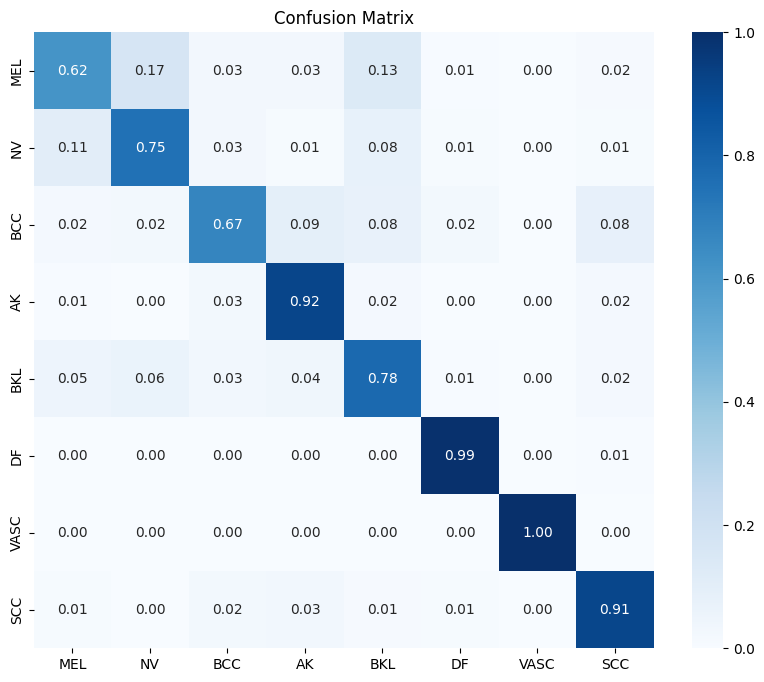

#####  val  #####
81/81 ━━━━━━━━━━━━━━━━━━━━ 107s 1s/step - accuracy: 0.6456 - auc: 0.9356 - loss: 1.0020 - precision: 0.6866 - recall: 0.6215
[0.9790946245193481, 0.6622925400733948, 0.9382842779159546, 0.6950234174728394, 0.6306445598602295]


100%|██████████| 81/81 [00:28<00:00,  2.79it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step
              precision    recall  f1-score   support

         MEL       0.60      0.58      0.59       510
          NV       0.87      0.73      0.79      1287
         BCC       0.66      0.59      0.63       332
          AK       0.38      0.60      0.46        87
         BKL       0.41      0.60      0.49       262
          DF       0.26      0.62      0.37        24
        VASC       0.83      0.77      0.80        26
         SCC       0.31      0.56      0.40        63

    accuracy                           0.66      2591
   macro avg       0.54      0.63      0.57      2591
weighted avg       0.71      0.66      0.68      2591



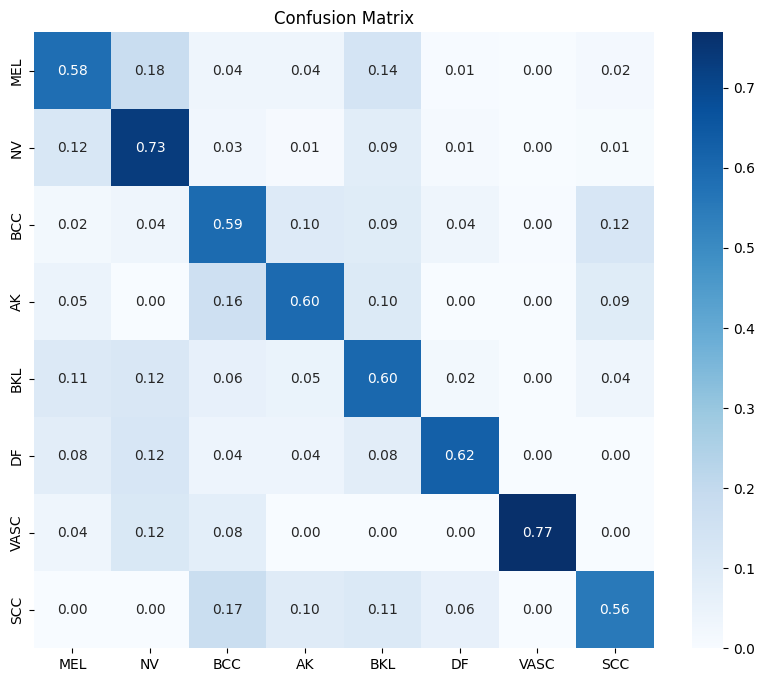

#####  test  #####
81/81 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - accuracy: 0.6623 - auc: 0.9395 - loss: 0.9633 - precision: 0.6980 - recall: 0.6329
[0.9819029569625854, 0.6597222089767456, 0.9378342628479004, 0.6934587359428406, 0.6257715821266174]


100%|██████████| 81/81 [00:29<00:00,  2.78it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step
              precision    recall  f1-score   support

         MEL       0.62      0.57      0.59       511
          NV       0.87      0.72      0.79      1288
         BCC       0.67      0.57      0.61       332
          AK       0.32      0.52      0.40        86
         BKL       0.44      0.70      0.54       263
          DF       0.26      0.58      0.36        24
        VASC       0.69      0.80      0.74        25
         SCC       0.27      0.56      0.37        63

    accuracy                           0.66      2592
   macro avg       0.52      0.63      0.55      2592
weighted avg       0.71      0.66      0.68      2592



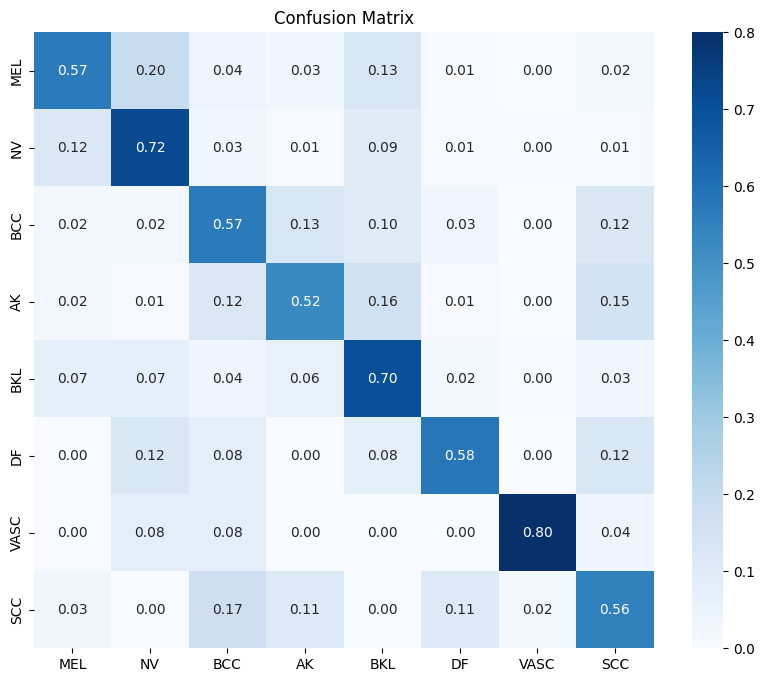

In [20]:
test_model(model, history, 'densenent121-no-segm', "/Users/mac/Development/diploma/skin-mutation-detection/models/results/densenet121-no-segm")